# Exploración de datos: AI vs Human Text Classification Benchmark (50k)

Este notebook se conserva **solo para la exploración de datos** (carga, EDA y análisis de limpieza).
La carga, el preprocesamiento, el entrenamiento, la evaluación y el registro en MLflow se migraron a `train.py` en la raíz del repositorio.

### Contenido
- **Paso 1:** carga y descripción del dataset
- **Paso 2:** análisis exploratorio (EDA)
- **Paso 3:** análisis de limpieza de datos


### 0. Instalación y configuración

In [1]:
!pip install -q kagglehub seaborn

In [2]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             RocCurveDisplay, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_columns", 40)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
PALETA = ["#4C72B0", "#DD8452"]

## Paso 1: Carga y descripción del dataset

In [3]:
import kagglehub

path = kagglehub.dataset_download("datascikhan/ai-vs-human-text-classification-benchmark-50k")
print("Path to dataset files:", path)

for root, _, files in os.walk(path):
    for f in files:
        fp = os.path.join(root, f)
        print(f"{f}  ({os.path.getsize(fp)/1e6:.1f} MB)")

100%|██████████| 15.1M/15.1M [00:00<00:00, 76.0MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/datascikhan/ai-vs-human-text-classification-benchmark-50k/versions/1
AI_vs_Human_Text_Classification_Benchmark.csv  (128.3 MB)


In [4]:
CSV_PATH = os.path.join(path, "AI_vs_Human_Text_Classification_Benchmark.csv")
df_raw = pd.read_csv(CSV_PATH)

TEXT_COL = "Raw_Text"
LABEL_COL = "Label"

print(f"Registros: {df_raw.shape[0]:,}")
print(f"Variables: {df_raw.shape[1]}")
df_raw.head()

Registros: 50,000
Variables: 30


,Text_ID,Raw_Text,Label,Source_Model,Model_Size,Model_Temperature,Generation_Prompt_Type,RAG_Context_Provided,Detection_Score_Benchmark_Model_A,Word_Count,Character_Count_Total,Sentence_Count,Average_Word_Length,Average_Sentence_Length_Words,Unique_Words_Count,Lexical_Diversity_Score,Punctuation_Count,Punctuation_Density,Special_Char_Count,Stopword_Count,Stopword_Density,Flesch_Kincaid_Grade_Level,Smog_Index,Average_Syllables_Per_Word,Contains_Code_Snippet,Capital_Letter_Count,Formal_Tone_Score,Emotion_Tone_Intensity,Coherence_Score,Burstiness_Score
0,TXT_09927,"History has always been a subject of intense debate. Some argue that history is overrated, while others believe alte...",0,Human_Origin,Human,NaN,Human_Writing,Human,21.510198,219,1639,28,6.251142,7.821429,81,0.369863,55,0.033557,0,96,0.438356,11.785556,12.522536,2.027397,0,28,100.000000,16.518485,81.544039,48.832741
1,TXT_35284,"When it comes Similarly, Philosophy, there are several schools of thought. The classical view emphasizes structure a...",0,Human_Origin,Human,NaN,Human_Writing,Human,78.303093,293,2220,36,6.331058,8.138889,80,0.273038,79,0.035586,0,134,0.457338,11.612546,11.958738,2.000000,0,37,100.000000,23.965492,93.325738,65.352863
2,TXT_27383,"Let me tell you about Programming. It's one of those topics that everyone has an opinion on, but few people truly un...",0,Human_Origin,Human,NaN,Human_Writing,Human,83.110976,161,1101,17,5.645963,9.470588,85,0.527950,41,0.037239,0,80,0.496894,11.031269,12.423615,1.850932,0,20,91.519314,31.751173,57.563496,58.196010
3,TXT_36542,"Have you ever considered the role of Travel in shaping our society? this easy to take travel for granted, but its im...",0,Human_Origin,Human,NaN,Human_Writing,Human,42.621955,106,656,10,4.990566,10.600000,72,0.679245,26,0.039634,0,53,0.500000,9.075098,11.429528,1.650943,0,11,54.611734,40.980060,42.889109,68.661004
4,TXT_23205,"In my experience with Psychology, I've noticed often the most significant changes that come from unexpected places. ...",0,Human_Origin,Human,NaN,Human_Writing,Human,100.000000,76,492,4,5.394737,19.000000,62,0.815789,8,0.016260,0,37,0.486842,13.749167,15.247665,1.842105,0,6,50.752909,43.610382,28.351032,44.903004


### Estructura: tipos, nulos y valores únicos

In [5]:
estructura = pd.DataFrame({
    "tipo": df_raw.dtypes.astype(str),
    "nulos": df_raw.isna().sum(),
    "valores_unicos": df_raw.nunique(),
    "ejemplo": [str(df_raw[c].dropna().iloc[0])[:50] for c in df_raw.columns],
})
estructura

,tipo,nulos,valores_unicos,ejemplo
Text_ID,object,0,50000,TXT_09927
Raw_Text,object,0,50000,History has always been a subject of intense debat
Label,int64,0,2,0
Source_Model,object,0,6,Human_Origin
Model_Size,object,0,4,Human
Model_Temperature,float64,25000,91,0.34
Generation_Prompt_Type,object,0,11,Human_Writing
RAG_Context_Provided,object,0,3,Human
Detection_Score_Benchmark_Model_A,float64,0,48107,21.51019834329092
Word_Count,int64,0,886,219


In [6]:
for v, nombre in [(0, "HUMANO"), (1, "IA")]:
    print(f"===== {nombre} =====")
    for t in df_raw.loc[df_raw[LABEL_COL] == v, TEXT_COL].sample(2, random_state=RANDOM_STATE):
        print("-", t[:400], "...\n")

===== HUMANO =====
- Have you ever considered the role of Business in shaping our society? It's easy to take business for granted, but its impact is profound. From static; to healthcare, business further every aspect of our lives. I recently read an article that highlighted some surprising trends in business, and it made me realize how much we still have to learn. Perhaps the most important lesson is that business is  ...

- Let me tell you about Music. It's one of those topics that everyone has an opinion on, it's few people truly understand. For instance, most people think that music is about X, when in reality but much more complex. I've spent a considerable amount of time researching music, and I can ...

===== IA =====
- General Knowledge represents a critical domain in contemporary discourse. With increasing attention on general knowledge, stakeholders are reevaluating traditional approaches. Data indicates that general knowledge is subject results significant variability based o

### Significado de las variables

El archivo tiene **50,000 registros y 30 variables**, que se agrupan así:

**Identificador, texto y etiqueta**
- `Text_ID`: identificador único del documento (50,000 valores distintos).
- `Raw_Text`: el texto a clasificar. Es la única entrada del modelo.
- `Label`: variable objetivo, `0 = humano`, `1 = IA`.

**Metadatos de generación** (describen cómo se creó el texto)
- `Source_Model`: modelo que lo generó (`Human_Origin`, `ChatGPT-4o`, `Claude-3.5-Sonnet`, `Gemini-1.5-Pro`, `Llama-3-70B`, `Mistral-Large`).
- `Model_Size`: tamaño del modelo (`Human`, `Medium`, `Large`, `Frontier`).
- `Model_Temperature`: temperatura de generación (vacía en los textos humanos).
- `Generation_Prompt_Type`: tipo de prompt (`Human_Writing` o 10 tipos como `Poem`, `Email_Draft`, `News_Style`).
- `RAG_Context_Provided`: si se usó contexto RAG (`Human`, `Yes`, `No`).
- `Detection_Score_Benchmark_Model_A`: puntaje (0 a 100) que le asignó otro detector de IA.

**Variables estilométricas precalculadas**
- Longitud: `Word_Count`, `Character_Count_Total`, `Sentence_Count`, `Average_Sentence_Length_Words`.
- Vocabulario: `Average_Word_Length`, `Unique_Words_Count`, `Lexical_Diversity_Score`, `Average_Syllables_Per_Word`.
- Puntuación y forma: `Punctuation_Count`, `Punctuation_Density`, `Special_Char_Count`, `Capital_Letter_Count`, `Contains_Code_Snippet`.
- Palabras funcionales: `Stopword_Count`, `Stopword_Density`.
- Legibilidad: `Flesch_Kincaid_Grade_Level`, `Smog_Index`.
- Puntajes de estilo: `Formal_Tone_Score`, `Emotion_Tone_Intensity`, `Coherence_Score`, `Burstiness_Score`.

Los metadatos de generación no se usan en el modelo: describen el proceso que produjo el texto y, como se ve en el EDA, delatan la etiqueta de forma directa.

## Paso 2: Análisis exploratorio (EDA)

### Balance de clases

clase
Humano    25000
IA        25000
Name: count, dtype: int64 

clase
Humano    50.0 %
IA        50.0 %
Name: count, dtype: object


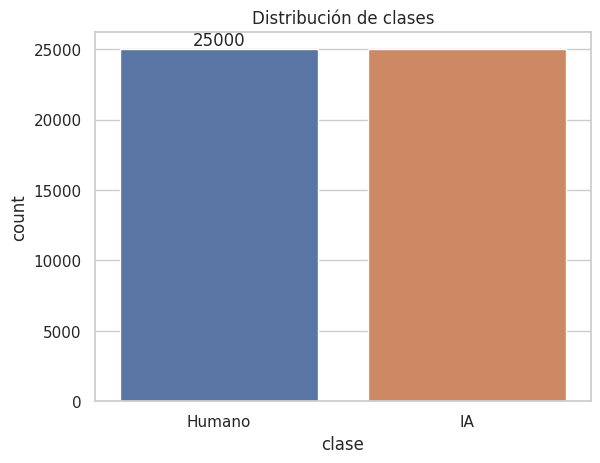

In [7]:
df_raw["clase"] = df_raw[LABEL_COL].map({0: "Humano", 1: "IA"})
conteo = df_raw["clase"].value_counts()
print(conteo, "\n")
print((conteo / conteo.sum() * 100).round(2).astype(str) + " %")

ax = sns.countplot(data=df_raw, x="clase", order=["Humano", "IA"], palette=PALETA)
ax.bar_label(ax.containers[0])
ax.set_title("Distribución de clases")
plt.show()

Las clases están perfectamente balanceadas (25,000 / 25,000). Un clasificador que siempre responde la misma clase obtiene 50% de accuracy, y ese es el piso contra el que se compara el modelo.

### Metadatos de generación contra la etiqueta

In [8]:
METADATOS = ["Source_Model", "Model_Size", "Generation_Prompt_Type", "RAG_Context_Provided"]
for c in METADATOS:
    print(f"\n===== {c} =====")
    print(pd.crosstab(df_raw[c], df_raw["clase"]))

print("\n===== Model_Temperature nula por clase =====")
print(pd.crosstab(df_raw["Model_Temperature"].isna(), df_raw["clase"]).rename(index={True: "nula", False: "con valor"}))


===== Source_Model =====
clase              Humano    IA
Source_Model                   
ChatGPT-4o              0  4963
Claude-3.5-Sonnet       0  4923
Gemini-1.5-Pro          0  5028
Human_Origin        25000     0
Llama-3-70B             0  5014
Mistral-Large           0  5072

===== Model_Size =====
clase       Humano     IA
Model_Size               
Frontier         0  14914
Human        25000      0
Large            0   5014
Medium           0   5072

===== Generation_Prompt_Type =====
clase                    Humano    IA
Generation_Prompt_Type               
Argumentative_Essay           0  2574
Creative_Writing              0  2479
Educational_Explanation       0  2562
Email_Draft                   0  2477
Human_Writing             25000     0
News_Style                    0  2491
Opinion_Piece                 0  2542
Poem                          0  2438
Product_Review                0  2436
Storytelling                  0  2450
Technical_Explanation         0  2551

===== R

Cada metadato separa las clases sin error: `Source_Model = Human_Origin`, `Model_Size = Human`, `Generation_Prompt_Type = Human_Writing` y `RAG_Context_Provided = Human` aparecen solo en los 25,000 textos humanos, y `Model_Temperature` está vacía exactamente en esos mismos registros. Usarlos como variables sería dataleak (el modelo leería la respuesta en lugar de aprenderla del texto), por eso se excluyen.

Los textos de IA se reparten casi por igual entre los 5 modelos (entre 4,923 y 5,072 cada uno) y entre los 10 tipos de prompt.

### Estadísticas descriptivas de las variables numéricas

In [9]:
NUM_COLS = ["Detection_Score_Benchmark_Model_A", "Word_Count", "Character_Count_Total", "Sentence_Count",
            "Average_Word_Length", "Average_Sentence_Length_Words", "Unique_Words_Count",
            "Lexical_Diversity_Score", "Punctuation_Count", "Punctuation_Density", "Special_Char_Count",
            "Stopword_Count", "Stopword_Density", "Flesch_Kincaid_Grade_Level", "Smog_Index",
            "Average_Syllables_Per_Word", "Capital_Letter_Count", "Formal_Tone_Score",
            "Emotion_Tone_Intensity", "Coherence_Score", "Burstiness_Score"]

df_raw[NUM_COLS].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
Detection_Score_Benchmark_Model_A,50000.0,58.542,20.608,0.000,44.310,58.202,72.404,100.000
Word_Count,50000.0,287.207,177.516,47.000,154.000,249.000,360.000,934.000
Character_Count_Total,50000.0,2250.745,1444.888,277.000,1162.000,1931.000,2863.000,7624.000
Sentence_Count,50000.0,34.079,23.341,2.000,17.000,29.000,44.000,126.000
Average_Word_Length,50000.0,6.488,0.582,4.027,6.137,6.516,6.988,7.936
Average_Sentence_Length_Words,50000.0,9.064,1.682,6.920,8.097,8.559,9.385,30.500
Unique_Words_Count,50000.0,76.391,9.264,38.000,73.000,78.000,83.000,93.000
Lexical_Diversity_Score,50000.0,0.372,0.203,0.074,0.214,0.319,0.503,0.925
Punctuation_Count,50000.0,72.916,51.339,3.000,35.000,61.000,96.000,300.000
Punctuation_Density,50000.0,0.031,0.005,0.008,0.028,0.030,0.036,0.049


In [10]:
df_raw.groupby("clase")[NUM_COLS].agg(["mean", "median"]).T.round(3)

clase                                       Humano        IA
Detection_Score_Benchmark_Model_A mean      60.321    56.764
                                  median    60.196    56.716
Word_Count                        mean     289.952   284.461
                                  median   251.000   246.000
Character_Count_Total             mean    2160.664  2340.825
                                  median  1848.000  2024.000
Sentence_Count                    mean      34.682    33.476
                                  median    29.000    29.000
Average_Word_Length               mean       6.034     6.943
                                  median     6.152     6.988
Average_Sentence_Length_Words     mean       9.234     8.894
                                  median     8.609     8.528
Unique_Words_Count                mean      80.746    72.036
                                  median    82.000    73.000
Lexical_Diversity_Score           mean       0.387     0.357
                                  median     0.336     0.302
Punctuation_Count                 mean      78.834    66.997
                                  median    66.000    57.000
Punctuation_Density               mean       0.035     0.027
                                  median     0.036     0.028
Special_Char_Count                mean       0.146     0.137
                                  median     0.000     0.000
Stopword_Count                    mean     130.506    89.878
                                  median   113.000    78.000
Stopword_Density                  mean       0.453     0.318
                                  median     0.452     0.317
Flesch_Kincaid_Grade_Level        mean      11.648    15.969
                                  median    11.831    15.987
Smog_Index                        mean      12.549    13.820
                                  median    12.486    13.689
Average_Syllables_Per_Word        mean       1.950     2.369
                                  median     1.981     2.381
Capital_Letter_Count              mean      37.228    35.814
                                  median    32.000    31.000
Formal_Tone_Score                 mean      88.185    50.059
                                  median   100.000    50.099
Emotion_Tone_Intensity            mean      29.943    29.993
                                  median    29.996    29.972
Coherence_Score                   mean      75.575    75.738
                                  median    77.455    76.874
Burstiness_Score                  mean      64.355    50.956
                                  median    62.716    48.526

### Relación de cada variable con la etiqueta (Spearman)

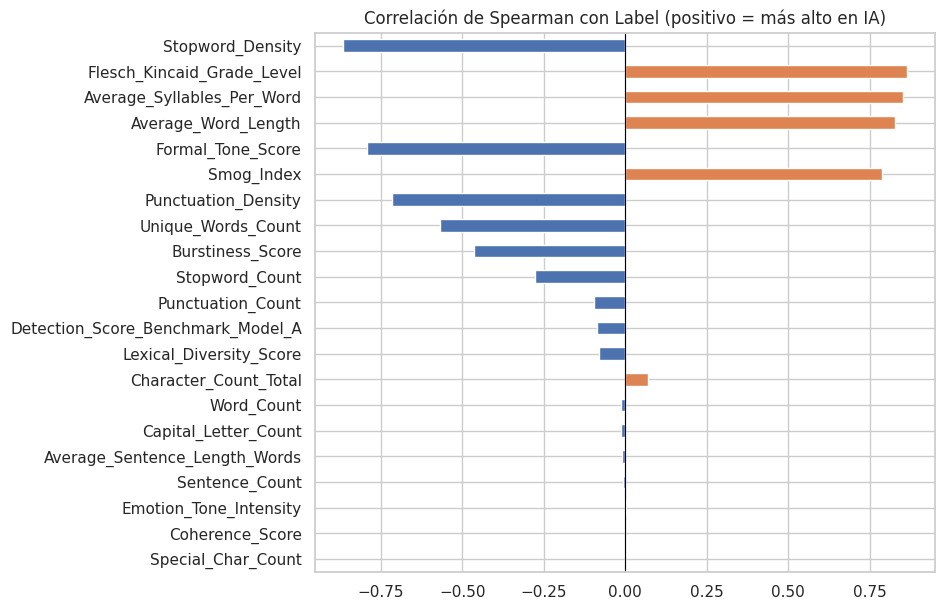

,Label
Stopword_Density,-0.866
Flesch_Kincaid_Grade_Level,0.864
Average_Syllables_Per_Word,0.852
Average_Word_Length,0.827
Formal_Tone_Score,-0.791
Smog_Index,0.786
Punctuation_Density,-0.717
Unique_Words_Count,-0.569
Burstiness_Score,-0.464
Stopword_Count,-0.277


In [11]:
corr_target = (df_raw[NUM_COLS + [LABEL_COL]].corr(method="spearman")[LABEL_COL]
               .drop(LABEL_COL).sort_values(key=abs, ascending=False))

plt.figure(figsize=(8, 7))
corr_target.plot.barh(color=[PALETA[1] if v > 0 else PALETA[0] for v in corr_target])
plt.axvline(0, color="black", lw=0.8)
plt.gca().invert_yaxis()
plt.title("Correlación de Spearman con Label (positivo = más alto en IA)")
plt.show()

corr_target.round(3)

2 Grupos:

- **Variables que casi separan las clases solas** (|ρ| > 0.7): `Stopword_Density` (humano 0.45 vs IA 0.32, ρ = -0.87), `Flesch_Kincaid_Grade_Level` (11.6 vs 16.0, ρ = 0.86), `Average_Syllables_Per_Word` (1.95 vs 2.37, ρ = 0.85), `Average_Word_Length` (6.0 vs 6.9, ρ = 0.83), `Formal_Tone_Score` (88 vs 50, ρ = -0.79), `Smog_Index` (ρ = 0.79) y `Punctuation_Density` (ρ = -0.72). Los textos de IA usan palabras más largas y menos palabras funcionales, por eso su nivel de lectura es más alto.
- **Variables sin relación con la etiqueta** (|ρ| < 0.1): la longitud (`Word_Count`, `Sentence_Count`, `Character_Count_Total`), `Capital_Letter_Count`, `Emotion_Tone_Intensity`, `Coherence_Score` y `Special_Char_Count`. La longitud está balanceada a propósito entre clases (mediana de 251 palabras en humanos y 246 en IA).

Dos hallazgos llaman la atención:
- `Formal_Tone_Score` es más alto en los textos humanos (mediana 100 vs 50), lo contrario de lo esperado. Sugiere que este puntaje se generó con una regla propia del dataset y no mide formalidad real.
- `Detection_Score_Benchmark_Model_A` casi no distingue las clases (ρ = -0.09): el detector de referencia del dataset funciona prácticamente al azar.

### Distribución de las variables más relevantes por clase

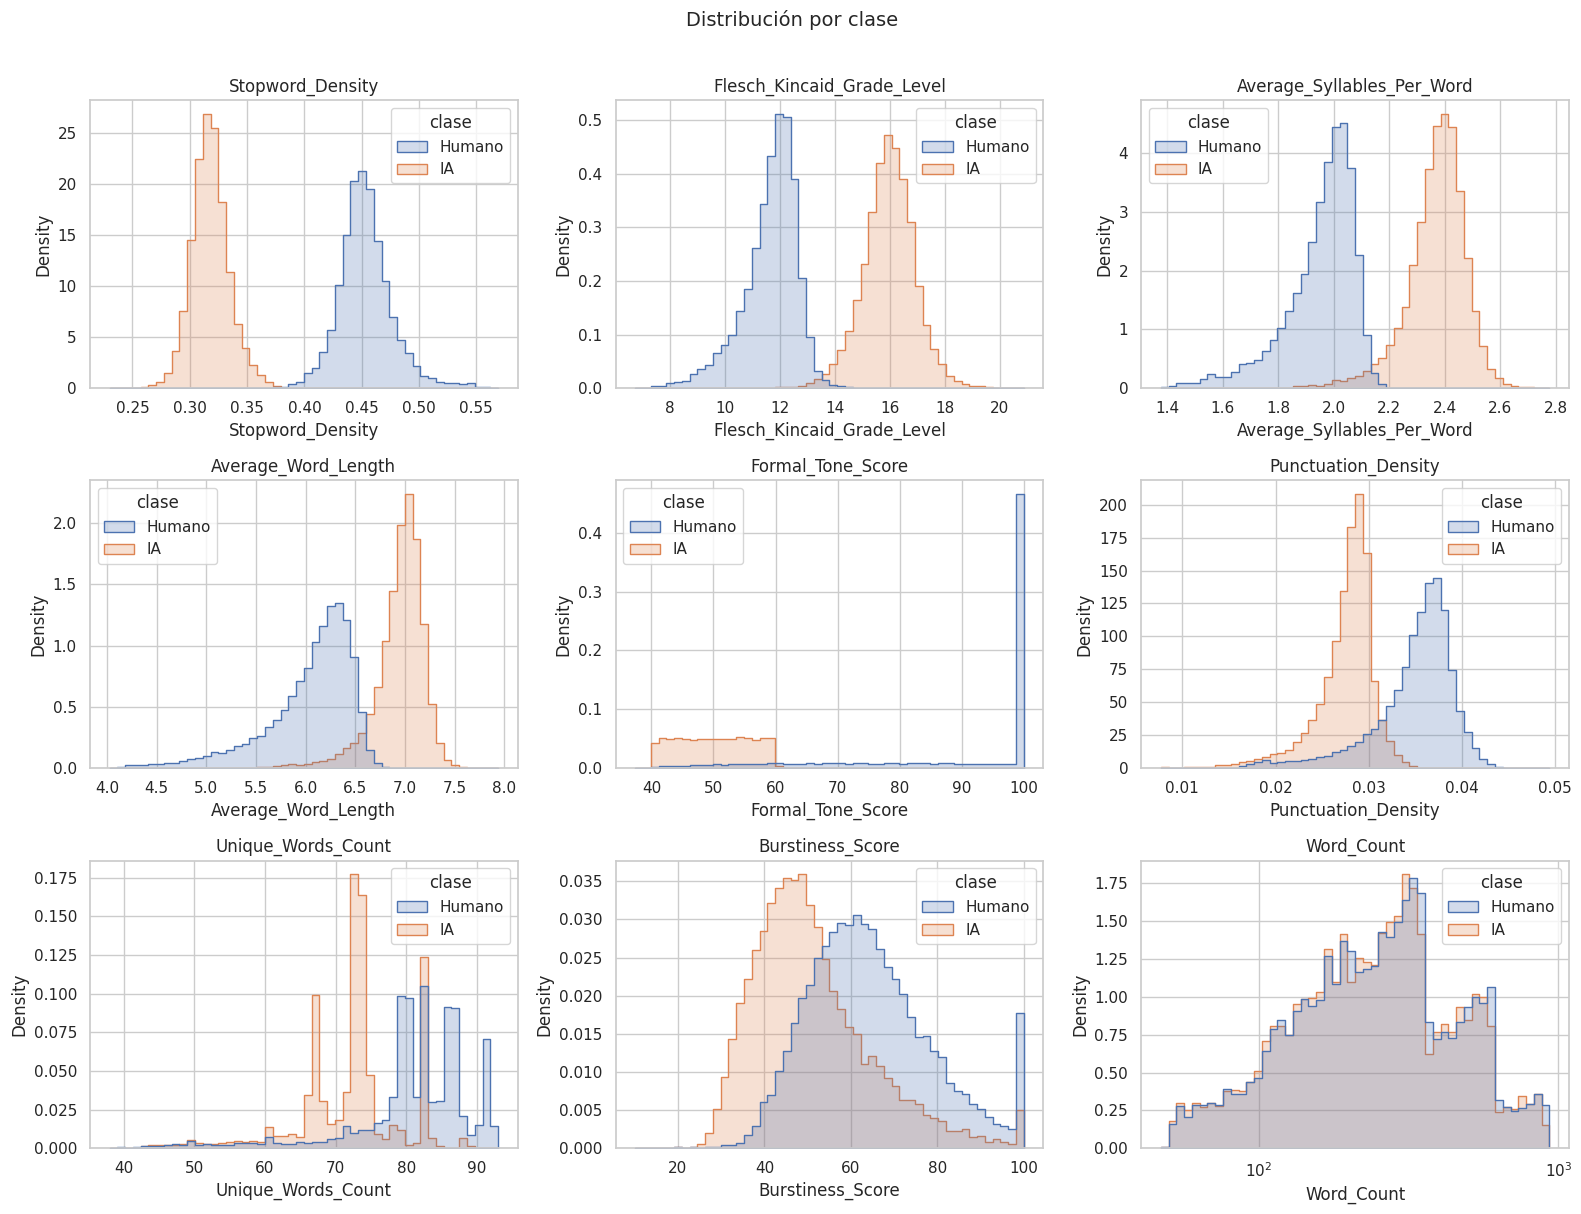

In [12]:
VARS_PLOT = ["Stopword_Density", "Flesch_Kincaid_Grade_Level", "Average_Syllables_Per_Word",
             "Average_Word_Length", "Formal_Tone_Score", "Punctuation_Density",
             "Unique_Words_Count", "Burstiness_Score", "Word_Count"]

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for ax, f in zip(axes.ravel(), VARS_PLOT):
    sns.histplot(data=df_raw, x=f, hue="clase", bins=50, stat="density", common_norm=False,
                 element="step", ax=ax, palette=PALETA, log_scale=(f == "Word_Count"))
    ax.set_title(f)
plt.suptitle("Distribución por clase", y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

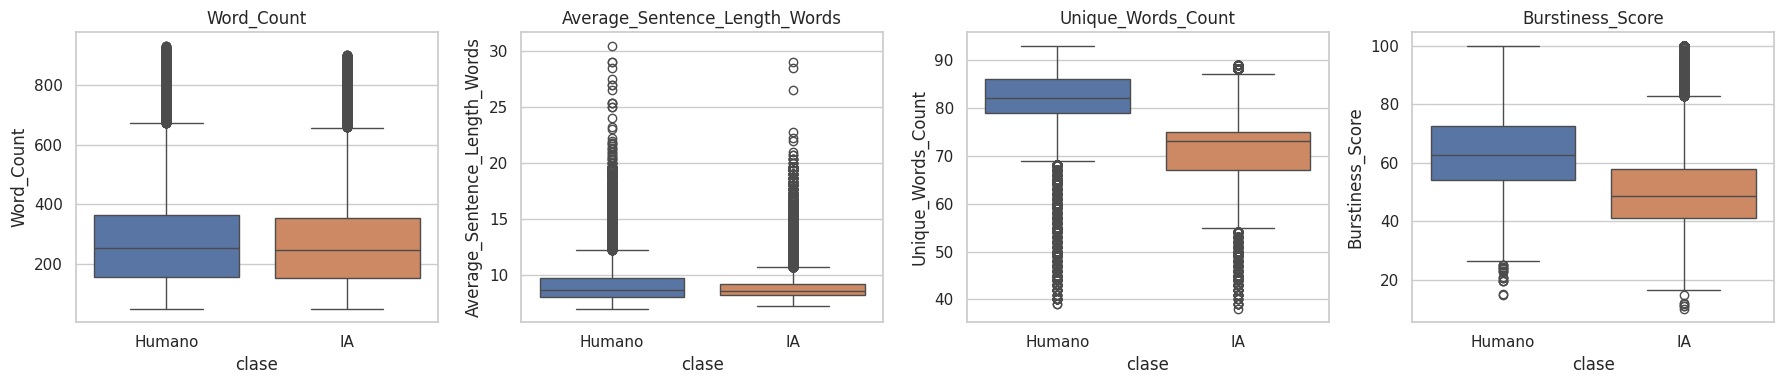

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, f in zip(axes, ["Word_Count", "Average_Sentence_Length_Words", "Unique_Words_Count", "Burstiness_Score"]):
    sns.boxplot(data=df_raw, x="clase", y=f, ax=ax, palette=PALETA)
    ax.set_title(f)
plt.tight_layout()
plt.show()

Las variables de legibilidad y vocabulario muestran distribuciones casi sin traslape entre clases, mientras que `Word_Count` es prácticamente idéntica en ambas. `Unique_Words_Count` nunca pasa de 93 aunque hay textos de más de 900 palabras, lo que indica que los textos repiten mucho las mismas frases. Los boxplots muestran colas largas en longitud y en `Average_Sentence_Length_Words`, que se revisan en la limpieza.

### Correlación entre variables

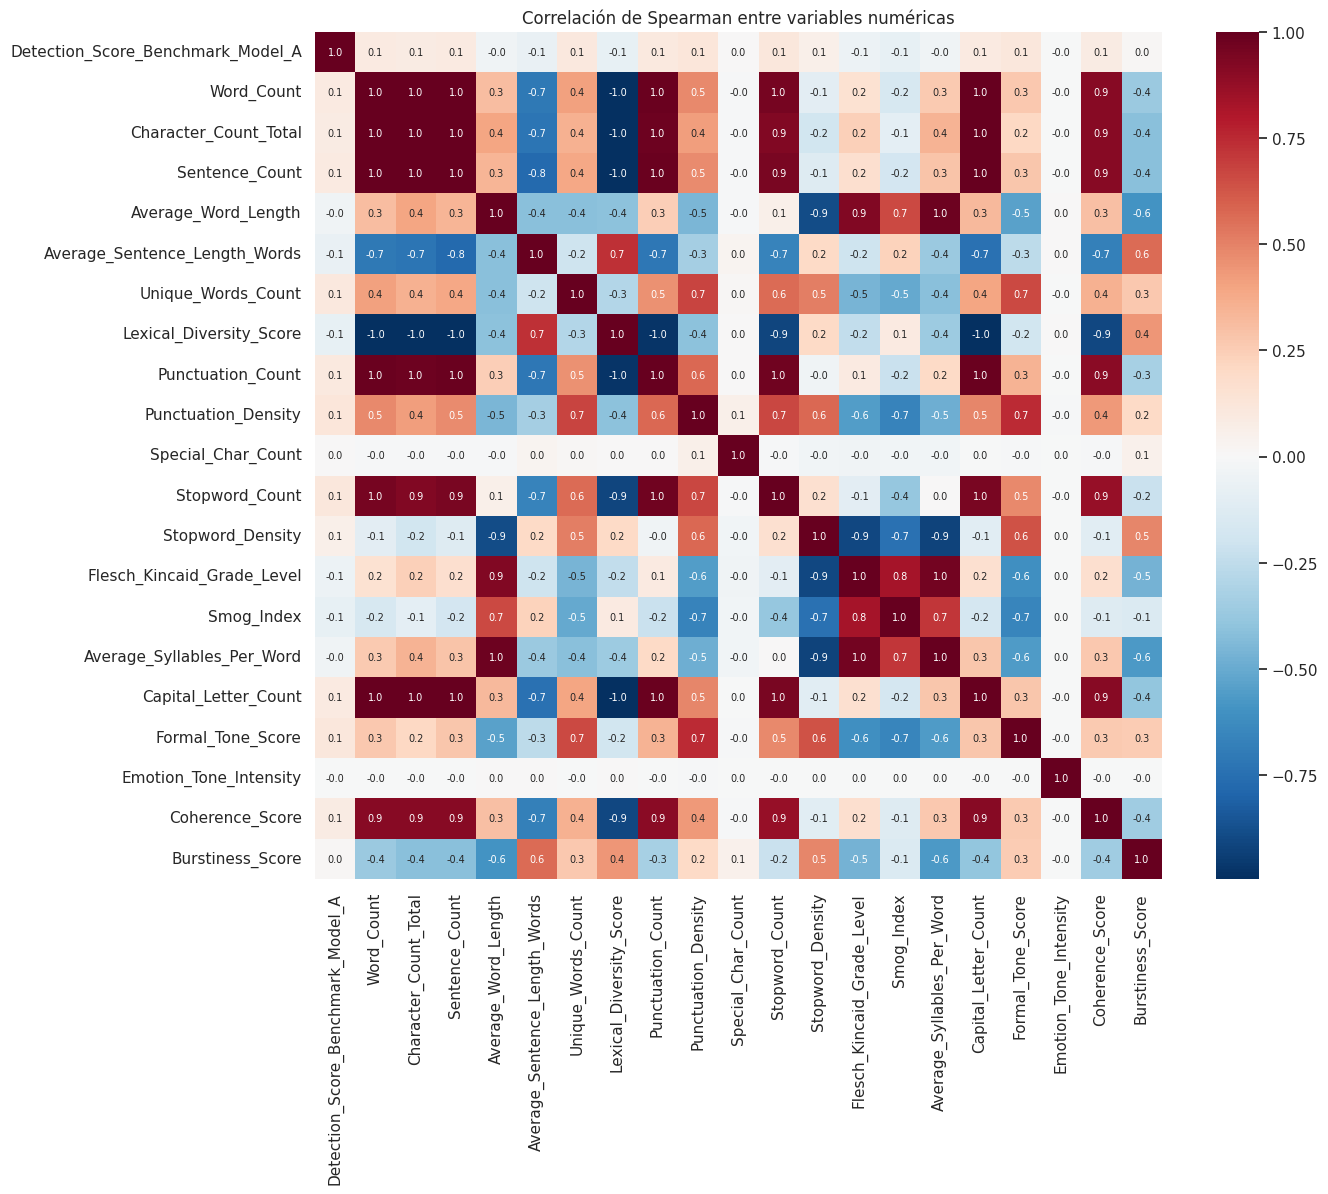

In [14]:
plt.figure(figsize=(14, 11))
sns.heatmap(df_raw[NUM_COLS].corr(method="spearman"), cmap="RdBu_r", center=0, annot=True, fmt=".1f",
            annot_kws={"size": 7}, square=True)
plt.title("Correlación de Spearman entre variables numéricas")
plt.show()

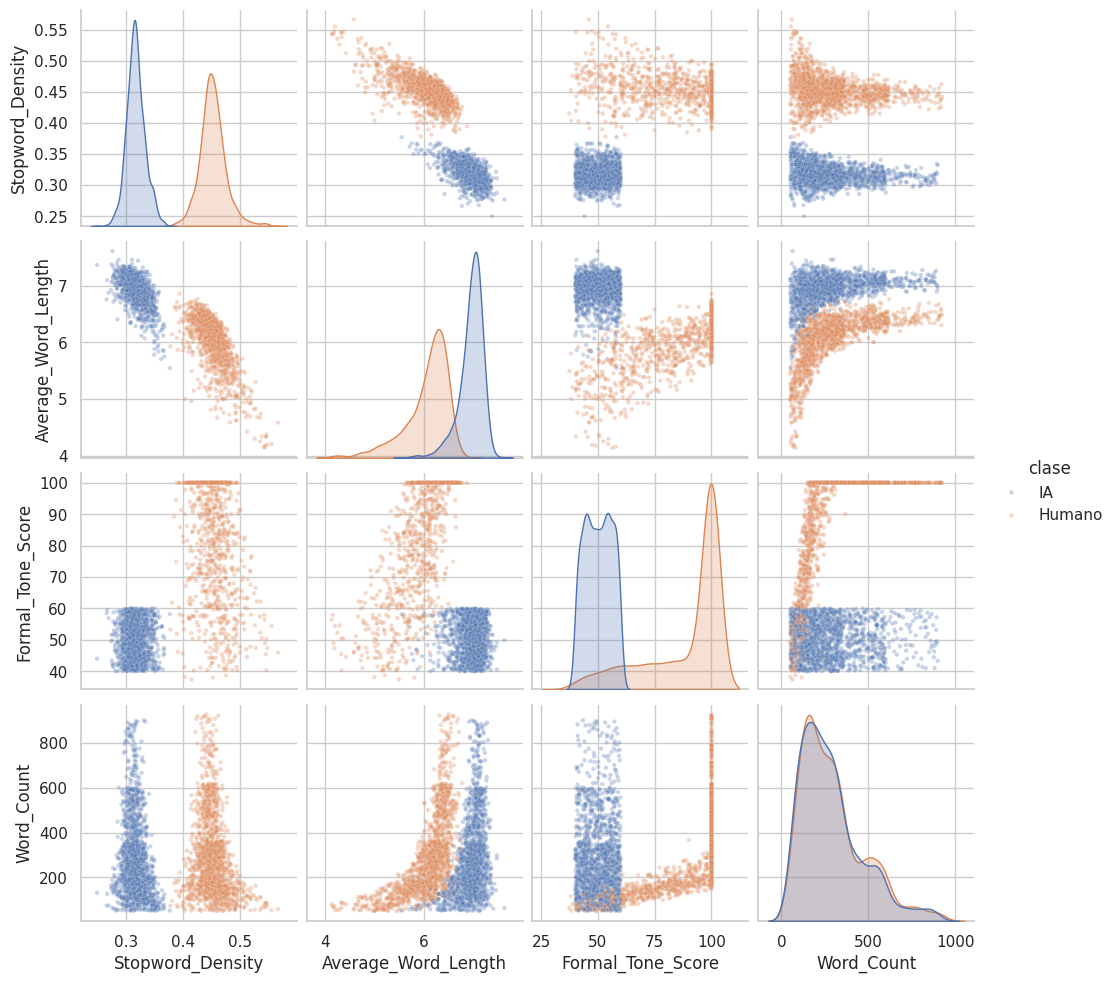

In [15]:
muestra = df_raw.sample(3000, random_state=RANDOM_STATE)
sns.pairplot(muestra, vars=["Stopword_Density", "Average_Word_Length", "Formal_Tone_Score", "Word_Count"],
             hue="clase", plot_kws={"alpha": 0.3, "s": 10}, palette=PALETA)
plt.show()

Las variables de longitud (`Word_Count`, `Character_Count_Total`, `Sentence_Count`, `Punctuation_Count`, `Stopword_Count`) están muy correlacionadas entre sí, igual que las de legibilidad (`Flesch_Kincaid_Grade_Level`, `Smog_Index`, `Average_Syllables_Per_Word`, `Average_Word_Length`), así que aportan información redundante. En el pairplot, `Stopword_Density` y `Average_Word_Length` forman dos nubes separadas, una por clase.

### Vocabulario por clase

In [16]:
cv = CountVectorizer(binary=True, token_pattern=r"(?u)\b[a-zA-Z]{3,}\b")
X_bin = cv.fit_transform(df_raw[TEXT_COL])
vocab = cv.get_feature_names_out()
y_all = df_raw[LABEL_COL].values

frac_hum = np.asarray(X_bin[y_all == 0].mean(axis=0)).ravel()
frac_ia = np.asarray(X_bin[y_all == 1].mean(axis=0)).ravel()
voc = pd.DataFrame({"palabra": vocab, "frac_docs_humano": frac_hum, "frac_docs_ia": frac_ia})

print(f"Palabras distintas (3+ letras) en los 50,000 textos: {len(vocab):,}")
print(f"Solo aparecen en textos humanos: {(voc.frac_docs_ia == 0).sum():,}")
print(f"Solo aparecen en textos de IA:   {(voc.frac_docs_humano == 0).sum():,}")

print("\nExclusivas de HUMANO más frecuentes:")
display(voc[voc.frac_docs_ia == 0].nlargest(10, "frac_docs_humano").round(3))
print("Exclusivas de IA más frecuentes:")
display(voc[voc.frac_docs_humano == 0].nlargest(10, "frac_docs_ia").round(3))

Palabras distintas (3+ letras) en los 50,000 textos: 1,493
Solo aparecen en textos humanos: 1,269
Solo aparecen en textos de IA:   149

Exclusivas de HUMANO más frecuentes:


,palabra,frac_docs_humano,frac_docs_ia
454,far,0.896,0.0
1013,reaching,0.896,0.0
45,alternative,0.887,0.0
1365,viewpoints,0.885,0.0
402,evidence,0.882,0.0
78,another,0.881,0.0
1164,supports,0.880,0.0
772,matter,0.878,0.0
225,conclusion,0.877,0.0
1441,worth,0.876,0.0


Exclusivas de IA más frecuentes:


,palabra,frac_docs_humano,frac_docs_ia
1232,these,0.0,0.972
807,moreover,0.0,0.945
860,notably,0.0,0.944
1046,research,0.0,0.943
14,addition,0.0,0.943
1126,specifically,0.0,0.942
1155,suggest,0.0,0.939
274,consistent,0.0,0.930
474,findings,0.0,0.927
1048,results,0.0,0.926


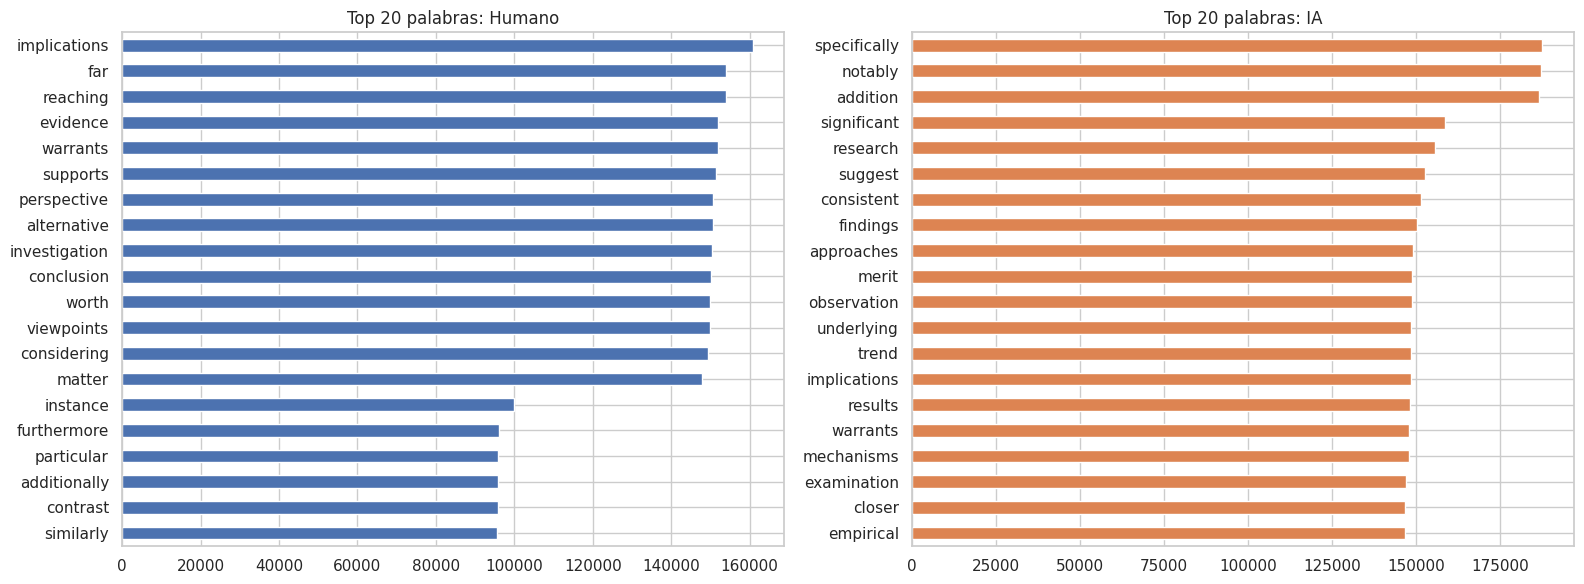

In [17]:
def top_palabras(textos, n=20):
    cv_top = CountVectorizer(stop_words="english", token_pattern=r"(?u)\b[a-zA-Z]{3,}\b")
    X = cv_top.fit_transform(textos)
    freqs = np.asarray(X.sum(axis=0)).ravel()
    idx = freqs.argsort()[::-1][:n]
    return pd.Series(freqs[idx], index=np.array(cv_top.get_feature_names_out())[idx])

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, (nombre, color) in zip(axes, zip(["Humano", "IA"], PALETA)):
    top = top_palabras(df_raw.loc[df_raw["clase"] == nombre, TEXT_COL])
    top[::-1].plot.barh(ax=ax, color=color)
    ax.set_title(f"Top 20 palabras: {nombre}")
plt.tight_layout()
plt.show()

### Hallazgos del EDA

- **Balance:** 25,000 textos por clase, por lo que accuracy es una métrica válida y el piso es 50%.
- **Fuga en metadatos:** `Source_Model`, `Model_Size`, `Generation_Prompt_Type`, `RAG_Context_Provided` y la nulidad de `Model_Temperature` identifican la clase sin error. Se excluyen del modelo.
- **Longitud no discrimina:** la distribución de palabras es prácticamente igual en ambas clases.
- **Estilo sí discrimina:** densidad de stopwords, legibilidad, sílabas y longitud media de palabra separan casi por completo las clases.
- **El dataset es sintético y basado en plantillas:** todo el corpus usa solo alrededor de 1,500 palabras distintas, y cada documento tiene como máximo 93 palabras únicas. Hay palabras que aparecen en cerca del 90% de los textos de una clase y en **ninguno** de la otra (por ejemplo *far*, *reaching*, *viewpoints*, *evidence* en humanos, y *these*, *moreover*, *notably*, *research*, *specifically* en IA). Los textos humanos siguen plantillas de opinión en primera persona ("Personally, I think...") y los de IA plantillas de tono académico ("represents a critical domain...", "stakeholders").
- **Consecuencia esperada:** cualquier modelo basado en palabras va a separar las clases casi perfectamente, porque los dos grupos usan vocabularios distintos.

## Paso 3: Limpieza de datos

Cada paso registra cuántas filas se pierden. El resumen final (`log_limpieza`) también se envía a MLflow.

In [18]:
log_limpieza = []
def registrar(paso, antes, despues, motivo):
    log_limpieza.append({"paso": paso, "filas_antes": antes, "filas_despues": despues,
                         "eliminadas": antes - despues, "motivo": motivo})
    print(f"[{paso}] {antes:,} -> {despues:,} (eliminadas: {antes - despues:,}). {motivo}")

dfc = df_raw.copy()

### 3.1 Tipos incorrectos y columnas sin información

- `Raw_Text` debe ser texto y `Label` entero 0/1.
- Las variables numéricas deben ser `float`/`int`; se fuerzan con `pd.to_numeric` para detectar valores no numéricos.
- `Text_ID` debe ser único.
- `Contains_Code_Snippet` tiene un solo valor (0) en todo el dataset, así que no aporta información y se elimina.

In [19]:
print("Tipo de Raw_Text:", dfc[TEXT_COL].map(type).value_counts().to_dict())
print("Valores de Label:", sorted(dfc[LABEL_COL].unique()))
print("Text_ID único:", dfc["Text_ID"].is_unique)

no_numericos = {c: int(pd.to_numeric(dfc[c], errors="coerce").isna().sum() - dfc[c].isna().sum()) for c in NUM_COLS}
print("Valores no numéricos en columnas numéricas:", {k: v for k, v in no_numericos.items() if v} or "ninguno")

dfc[TEXT_COL] = dfc[TEXT_COL].astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
dfc[LABEL_COL] = dfc[LABEL_COL].astype(int)

constantes = [c for c in dfc.columns if dfc[c].nunique(dropna=False) == 1]
print("Columnas constantes:", constantes)
dfc = dfc.drop(columns=constantes)

Tipo de Raw_Text: {<class 'str'>: 50000}
Valores de Label: [np.int64(0), np.int64(1)]
Text_ID único: True
Valores no numéricos en columnas numéricas: ninguno
Columnas constantes: ['Contains_Code_Snippet']


**Resultado:** no hubo tipos incorrectos. `Raw_Text` es texto en los 50,000 registros, `Label` solo toma 0 y 1, `Text_ID` es único y todas las columnas numéricas se leyeron como numéricas. Se eliminó `Contains_Code_Snippet` por ser constante.

### 3.2 Consistencia de las variables precalculadas

In [20]:
conteo_real = dfc[TEXT_COL].str.split().str.len()
dif = conteo_real - dfc["Word_Count"]
print(f"Word_Count coincide con el conteo por espacios: {(dif == 0).mean():.1%}")
print("Diferencia (real - Word_Count):", dif.describe()[["min", "50%", "max"]].to_dict())

ld = (dfc["Unique_Words_Count"] / dfc["Word_Count"] - dfc["Lexical_Diversity_Score"]).abs()
print(f"Lexical_Diversity_Score = Unique_Words_Count / Word_Count: {(ld < 0.01).mean():.1%}")

Word_Count coincide con el conteo por espacios: 30.5%
Diferencia (real - Word_Count): {'min': -42.0, '50%': -2.0, 'max': 4.0}
Lexical_Diversity_Score = Unique_Words_Count / Word_Count: 100.0%


`Word_Count` coincide exactamente con el conteo por espacios en cerca del 30% de los textos; en el resto la diferencia es pequeña (mediana de -2 palabras) y se explica por la forma de separar tokens. `Lexical_Diversity_Score` es exactamente `Unique_Words_Count / Word_Count`. **Decisión:** se conservan tal cual, porque son consistentes y solo se usan en el EDA, no en el modelo.

### 3.3 Valores faltantes

La única columna con nulos es `Model_Temperature` (25,000 nulos). Son **faltantes estructurales**: un texto humano no tiene temperatura de generación.

**Decisiones:**
- `Model_Temperature` **no se imputa**: rellenarla inventaría un dato que no existe, y además es un metadato excluido del modelo.
- Se eliminarían las filas con texto vacío o sin etiqueta, porque no se puede imputar un texto ni una etiqueta.

In [21]:
print(dfc.isna().sum()[dfc.isna().sum() > 0])
print("Textos vacíos:", int((dfc[TEXT_COL] == "").sum()))

antes = len(dfc)
dfc = dfc[(dfc[TEXT_COL] != "") & dfc[LABEL_COL].notna()]
registrar("faltantes", antes, len(dfc), "Texto vacío o etiqueta nula")

Model_Temperature    25000
dtype: int64
Textos vacíos: 0
[faltantes] 50,000 -> 50,000 (eliminadas: 0). Texto vacío o etiqueta nula


### 3.4 Duplicados

Si el mismo texto queda en entrenamiento y en prueba, el modelo lo "memoriza" y las métricas se inflan.

**Decisiones:**
- Se compara el texto normalizado (minúsculas y espacios simples) para detectar duplicados casi exactos.
- Textos repetidos con etiquetas contradictorias se eliminan completos.
- Textos repetidos con la misma etiqueta se dejan en una sola copia.

In [22]:
dfc["_texto_norm"] = dfc[TEXT_COL].str.lower()

print("Text_ID duplicados:", int(dfc["Text_ID"].duplicated().sum()))
print("Textos duplicados (normalizados):", int(dfc["_texto_norm"].duplicated().sum()))

etiquetas_por_texto = dfc.groupby("_texto_norm")[LABEL_COL].nunique()
contradictorios = etiquetas_por_texto[etiquetas_por_texto > 1].index
print("Textos con etiquetas contradictorias:", len(contradictorios))

antes = len(dfc)
dfc = dfc[~dfc["_texto_norm"].isin(contradictorios)]
registrar("etiquetas_contradictorias", antes, len(dfc), "Mismo texto con etiqueta 0 y 1")

antes = len(dfc)
dfc = dfc.drop_duplicates(subset=["_texto_norm"], keep="first").drop(columns="_texto_norm")
registrar("duplicados", antes, len(dfc), "Texto repetido, se conserva una copia")

Text_ID duplicados: 0
Textos duplicados (normalizados): 0
Textos con etiquetas contradictorias: 0
[etiquetas_contradictorias] 50,000 -> 50,000 (eliminadas: 0). Mismo texto con etiqueta 0 y 1
[duplicados] 50,000 -> 50,000 (eliminadas: 0). Texto repetido, se conserva una copia


**Resultado:** no hay duplicados ni etiquetas contradictorias. Aunque los textos se generan con plantillas, la combinación de frases hace que los 50,000 documentos sean distintos.

### 3.5 Outliers

**Criterio:** IQR sobre `log(Word_Count)`, porque la longitud tiene cola larga a la derecha y en escala logarítmica el IQR funciona mejor.

**Decisiones:**
- **Textos demasiado cortos** (debajo del límite inferior, con un mínimo de 5 palabras): se eliminan, porque no tienen suficiente información de estilo.
- **Textos largos:** se conservan. Son textos válidos y TF-IDF normaliza por documento.
- **Outliers en las variables estilométricas:** se reportan con IQR pero **no se eliminan**. Son valores posibles del estilo de un texto (no errores de captura) y estas variables no entran al modelo.

In [23]:
log_pal = np.log1p(dfc["Word_Count"])
q1, q3 = log_pal.quantile([0.25, 0.75])
iqr = q3 - q1
lim_inf_pal = max(5, int(np.expm1(q1 - 1.5 * iqr)))
lim_sup_pal = int(np.expm1(q3 + 1.5 * iqr))
print(f"Rango real de Word_Count: {dfc['Word_Count'].min()} a {dfc['Word_Count'].max()}")
print(f"Límites IQR (escala log): {lim_inf_pal} a {lim_sup_pal} palabras")

outliers_iqr = {}
for c in NUM_COLS:
    a, b = dfc[c].quantile([0.25, 0.75])
    r = b - a
    outliers_iqr[c] = int(((dfc[c] < a - 1.5 * r) | (dfc[c] > b + 1.5 * r)).sum())
print("\nOutliers por IQR (se conservan):")
print(pd.Series(outliers_iqr).sort_values(ascending=False).head(8))

antes = len(dfc)
dfc = dfc[dfc["Word_Count"] >= lim_inf_pal]
registrar("outliers_cortos", antes, len(dfc), f"Menos de {lim_inf_pal} palabras")

Rango real de Word_Count: 47 a 934
Límites IQR (escala log): 42 a 1282 palabras

Outliers por IQR (se conservan):
Average_Sentence_Length_Words    3833
Unique_Words_Count               2218
Word_Count                       2051
Special_Char_Count               2024
Sentence_Count                   2001
Character_Count_Total            1992
Capital_Letter_Count             1927
Punctuation_Count                1847
dtype: int64
[outliers_cortos] 50,000 -> 50,000 (eliminadas: 0). Menos de 42 palabras


**Resultado:** los textos van de 47 a 934 palabras y los límites IQR en escala log son 42 y ~1,280, así que ningún texto queda fuera del rango y no se elimina ninguno. En escala lineal sí aparecen outliers en varias variables (por ejemplo ~3,800 en `Average_Sentence_Length_Words`, ~2,200 en `Unique_Words_Count` y ~2,000 en `Word_Count`), pero corresponden a textos más largos o con oraciones más largas, no a errores.

### 3.6 Resumen de limpieza

In [24]:
resumen_limpieza = pd.DataFrame(log_limpieza)
display(resumen_limpieza)
print(f"\nFilas originales: {len(df_raw):,} | Filas finales: {len(dfc):,} ({len(dfc)/len(df_raw)*100:.1f}% conservado)")
print("Balance final:", dfc[LABEL_COL].value_counts().to_dict())

COLS_EXCLUIDAS = METADATOS + ["Model_Temperature", "Detection_Score_Benchmark_Model_A", "Text_ID"]
df_model = dfc[[TEXT_COL, LABEL_COL]].reset_index(drop=True)
print("Columnas usadas por el modelo:", list(df_model.columns))

,paso,filas_antes,filas_despues,eliminadas,motivo
0,faltantes,50000,50000,0,Texto vacío o etiqueta nula
1,etiquetas_contradictorias,50000,50000,0,Mismo texto con etiqueta 0 y 1
2,duplicados,50000,50000,0,"Texto repetido, se conserva una copia"
3,outliers_cortos,50000,50000,0,Menos de 42 palabras



Filas originales: 50,000 | Filas finales: 50,000 (100.0% conservado)
Balance final: {0: 25000, 1: 25000}
Columnas usadas por el modelo: ['Raw_Text', 'Label']


Se conservan los 50,000 registros y el balance 25,000 / 25,000. Los cambios fueron eliminar la columna constante `Contains_Code_Snippet`, documentar los nulos estructurales de `Model_Temperature` y excluir del modelo los metadatos con fuga (`Source_Model`, `Model_Size`, `Generation_Prompt_Type`, `RAG_Context_Provided`, `Model_Temperature`), el puntaje de otro detector (`Detection_Score_Benchmark_Model_A`) y el identificador `Text_ID`.

## Siguiente paso

El modelo se entrena y registra en MLflow con `train.py`. Ejemplo:

```bash
python train.py --data-path data/AI_vs_Human_Text_Classification_Benchmark.csv
```